# Latent Semantic Analysis (LSA)
LSA helps identify patterns (concepts) by examining how words co-occur across different documents. It is based on SVD, which reduces the dimension of the document-term matrix.

In [163]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
import nltk
from nltk.corpus import brown
import matplotlib.pyplot as plt
import numpy as np

## Data

**In this example, we use the brown corpus.**

The Brown Corpus was a carefully compiled selection of current American English, totalling about a million words drawn from a wide variety of sources. 

** We want to represent the reduced dataset in a new space of lower dimension using LSA.**

In [164]:
nltk.download('brown')

# Get 2 categories and 5 sentences from each
categories = ['reviews', 'romance']
documents = []
nb_doc_cat = 50
for cat in categories:
    sents = brown.sents(categories=cat)[:nb_doc_cat]
    docs = [" ".join(sent) for sent in sents]
    documents.extend(docs)

[nltk_data] Downloading package brown to
[nltk_data]     /Users/farida.zehraoui/nltk_data...
[nltk_data]   Package brown is already up-to-date!


In [165]:
print(len(documents))

100


In [166]:
cat_review = np.zeros(nb_doc_cat, int)
print(type(cat_review))
cat_romance = np.ones(nb_doc_cat, int)
print(type(cat_romance))
labels = np.concatenate((cat_review, cat_romance)) 
print(len(labels))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
100


In [167]:
print(documents[1:5])

['Certainly not in Orchestra Hall where he has played countless recitals , and where Thursday night he celebrated his 20th season with the Chicago Symphony Orchestra , playing the Brahms Concerto with his own slashing , demon-ridden cadenza melting into the high , pale , pure and lovely song with which a violinist unlocks the heart of the music , or forever finds it closed .', 'There was about that song something incandescent , for this Brahms was Milstein at white heat .', 'Not the noblest performance we have heard him play , or the most spacious , or even the most eloquent .', "Those would be reserved for the orchestra's great nights when the soloist can surpass himself ."]


## LSA

The first step before applying LSA is to Preprocessing (e.g., stemming, removing stop words, tokenization,  normalization (e.g., lemmatization/stemming),  filtering, ... ).
In this notebook, we only apply a tf-idf vectorizer.



**TF-IDF Vectorizer**


In [168]:
vectorizer = TfidfVectorizer(max_df=0.5, min_df=2, stop_words='english')
X = vectorizer.fit_transform(documents)
print("X shape:", X.shape)

X shape: (100, 99)


**We can now apply LSA to the preprocessed data. .**

In [169]:
nb_components = 90
# instanciate a SVD object
svd_model = TruncatedSVD(nb_components, random_state=42)

# fit the object to the data
reduced_data = svd_model.fit_transform(X)



In [170]:
print(reduced_data.shape)

(100, 90)


## Choice of number of components

In [182]:
variance = svd_model.explained_variance_ratio_
#print("Explained variance ratio:", variance)
#print("Cumulative explained variance:", variance.cumsum())

In [183]:
print(svd_model.explained_variance_ratio_.sum())

0.9999999999999999


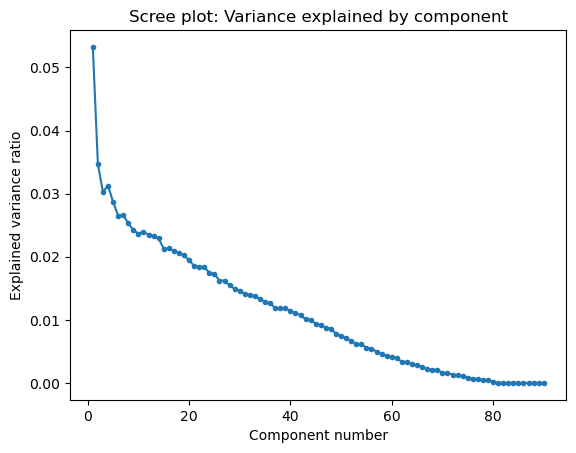

In [184]:
# plot the explained variance of each component
plt.plot(np.arange(1,nb_components+1),variance, marker='.')
plt.title("Scree plot: Variance explained by component")
plt.ylabel("Explained variance ratio")
plt.xlabel("Component number")
plt.show()

**This plot shows the variance explained by each component.**

We can also look at the explained variance ratio of each component: it is the percentage of the total variance explained by each component. Looking at this ratio, and more specifically at the cumulative ratio (% of total variance explained by multiple components) will help us decide how many components to keep.

In [185]:
def cumulative_var(p):
    reduceddim = svd_model.explained_variance_ratio_[:p]
    return np.cumsum(reduceddim*100)
print(cumulative_var(3))


[ 5.32483758  8.78928294 11.81560152]


**Cumulative variance plot**

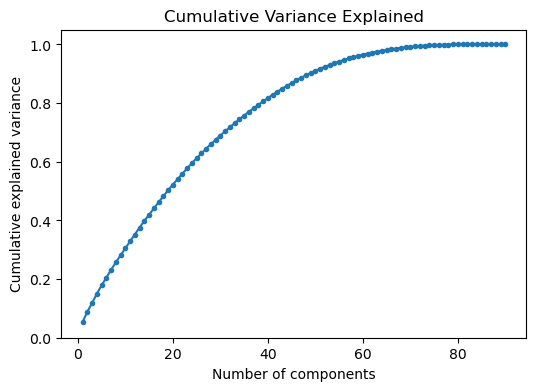

In [186]:
plt.figure(figsize=(6,4))
plt.plot(range(1, nb_components+1), variance.cumsum(), marker='.')
plt.title("Cumulative Variance Explained")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.ylim(0, 1.05)
plt.show()


In [176]:
def sum_var(p):
    reduceddim = svd_model.explained_variance_ratio_[:p]
    return sum(reduceddim*100)
print(sum_var(3))

3
11.815601517656821


**This plot shows how much of the total variance is explained by the `x` first components. Dimensionality reduction is a compromise: we want to keep the lowest number of factors, while still explaining a good percentage of the variance.**

In [177]:
print(reduced_data.shape)

(100, 90)


**3D Visualization (only if ≥3 components)**

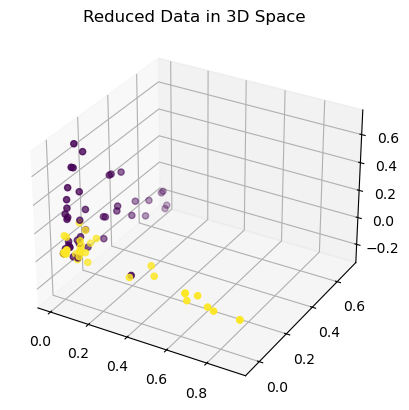

In [179]:
if reduced_data.shape[1] >= 3:
    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')
    #categories = ['reviews', 'romance']
    ax.scatter(reduced_data[:,0], reduced_data[:,1], reduced_data[:,2], c=labels)
    plt.title("Reduced Data in 3D Space")
    plt.show()
else:
    print("Not enough components for 3D visualization.")